In [6]:

import nbformat

source_path = ROOT / "Notebooks" / "12_multifeature_cnn.ipynb"
source_nb = nbformat.read(source_path, as_version=4)

print("Source notebook:", source_path.name)
print("Total cells:", len(source_nb.cells))

for i, cell in enumerate(source_nb.cells):
    text = cell.source.strip()
    if not text:
        continue

    if cell.cell_type == "markdown":
        print(f"\n--- MARKDOWN CELL {i} ---")
        print(text[:1500])
    elif cell.cell_type == "code":
        print(f"\n--- CODE CELL {i} ---")
        print(text[:2000])


Source notebook: 12_multifeature_cnn.ipynb
Total cells: 111

--- MARKDOWN CELL 0 ---
# 12 — Multi-Feature CNN (Main Deep-Learning Experiment)

Uses three complementary channels: Mel spectrogram, MFCC, and chroma. The same patient-wise split, compact architecture, training-only augmentation, validation early stopping, and class-weighted loss are used as in the one-channel baseline. Compare macro F1 and per-class performance, not accuracy alone.

--- CODE CELL 1 ---
from pathlib import Path
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import soundfile as sf
import librosa

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("PyTor

In [7]:

from pathlib import Path
import pandas as pd
import json

# Find the project root safely from the notebook's current directory
CURRENT = Path.cwd()

ROOT = next(
    (
        p for p in [CURRENT, *CURRENT.parents]
        if (p / "Notebooks").is_dir()
        and (p / "data").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        f"Could not locate project root from {CURRENT}"
    )

BASELINE_DIR = ROOT / "data/processed/deep_learning/cnn_baseline"
MULTIFEATURE_DIR = ROOT / "data/processed/deep_learning/multifeature_cnn"
EXPERIMENT_12B_DIR = ROOT / "data/processed/deep_learning/multifeature_cnn_12b"

print("PROJECT ROOT:", ROOT)
print("\n=== EXISTING EXPERIMENT ARTIFACTS ===")

for folder in [BASELINE_DIR, MULTIFEATURE_DIR, EXPERIMENT_12B_DIR]:
    print(f"\n{folder.relative_to(ROOT)}")

    if not folder.exists():
        print("  Directory not found")
        continue

    for path in sorted(folder.iterdir()):
        if path.is_file():
            print(f"  {path.name} ({path.stat().st_size:,} bytes)")

print("\n=== SAVED METRICS ===")

metric_files = [
    BASELINE_DIR / "cnn_baseline_metrics.csv",
    MULTIFEATURE_DIR / "multifeature_cnn_metrics.csv",
    EXPERIMENT_12B_DIR / "metrics.csv",
]

for path in metric_files:
    print(f"\n--- {path.name} ---")

    if path.exists():
        display(pd.read_csv(path))
    else:
        print("Not found")

print("\n=== SPLIT MANIFESTS ===")

for name in [
    "train_cnn_manifest.csv",
    "validation_cnn_manifest.csv",
    "test_cnn_manifest.csv",
]:
    path = BASELINE_DIR / name

    if path.exists():
        df = pd.read_csv(path)
        print(
            f"{name}: {len(df):,} cycles, "
            f"{df['patient_id'].nunique()} patients, "
            f"{df['diagnosis'].nunique()} diagnoses"
            if "diagnosis" in df.columns
            else f"{name}: {len(df):,} cycles, "
                 f"{df['patient_id'].nunique()} patients"
        )
    else:
        print(f"MISSING: {name}")


PROJECT ROOT: /Users/vs/Sem 5/Respiratory-Disease-Classification

=== EXISTING EXPERIMENT ARTIFACTS ===

data/processed/deep_learning/cnn_baseline
  best_lightweight_mel_cnn.pt (310,935 bytes)
  cnn_architecture.json (253 bytes)
  cnn_baseline_experiment_summary.csv (500 bytes)
  cnn_baseline_metrics.csv (309 bytes)
  cnn_patient_disjoint_manifest.csv (888,179 bytes)
  cnn_split_summary.csv (71 bytes)
  cnn_test_predictions.csv (223,653 bytes)
  cnn_training_class_weights.csv (307 bytes)
  cnn_training_config.json (459 bytes)
  cnn_training_history.csv (3,380 bytes)
  test_cnn_manifest.csv (198,749 bytes)
  train_cnn_manifest.csv (567,285 bytes)
  validation_cnn_manifest.csv (122,343 bytes)

data/processed/deep_learning/multifeature_cnn
  best_multifeature_cnn.pt (464,538 bytes)
  cnn_baseline_vs_multifeature_comparison.csv (485 bytes)
  disease_level_cnn_comparison.csv (478 bytes)
  final_cnn_experiment_comparison.csv (576 bytes)
  multifeature_cnn_confusion_matrix.csv (275 bytes)
  m

,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,best_epoch,best_validation_loss,test_samples,test_patients
0,Lightweight Mel CNN,0.716848,0.310168,0.213023,0.265858,0.21288,0.768721,32,1.207017,1561,25



--- multifeature_cnn_metrics.csv ---


,model,best_epoch,best_validation_loss,test_samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Multi-Feature CNN,1,2.452791,1561,0.855221,0.166417,0.14272,0.166417,0.15366,0.789662



--- metrics.csv ---


,model,best_epoch,best_validation_loss,test_samples,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,Regularized Multi-Feature CNN (12B),2,1.332201,1561,0.856502,0.166667,0.14275,0.166667,0.153784,0.790299



=== SPLIT MANIFESTS ===
train_cnn_manifest.csv: 4,423 cycles, 82 patients, 8 diagnoses
validation_cnn_manifest.csv: 914 cycles, 19 patients, 6 diagnoses
test_cnn_manifest.csv: 1,561 cycles, 25 patients, 6 diagnoses


In [8]:

import pandas as pd
import numpy as np

BASELINE_DIR = ROOT / "data/processed/deep_learning/cnn_baseline"

train_manifest = pd.read_csv(BASELINE_DIR / "train_cnn_manifest.csv")
val_manifest = pd.read_csv(BASELINE_DIR / "validation_cnn_manifest.csv")
test_manifest = pd.read_csv(BASELINE_DIR / "test_cnn_manifest.csv")

# Confirm that patients do not cross split boundaries
train_patients = set(train_manifest["patient_id"])
val_patients = set(val_manifest["patient_id"])
test_patients = set(test_manifest["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("Patient-disjoint verification: PASSED")
print(
    f"Train: {len(train_manifest)} cycles, "
    f"{len(train_patients)} patients"
)
print(
    f"Validation: {len(val_manifest)} cycles, "
    f"{len(val_patients)} patients"
)
print(
    f"Test: {len(test_manifest)} cycles, "
    f"{len(test_patients)} patients"
)

# Show disease counts using the existing manifests
class_column = (
    "diagnosis"
    if "diagnosis" in train_manifest.columns
    else "disease_label"
)

class_counts = pd.DataFrame({
    "Train": train_manifest[class_column].value_counts(),
    "Validation": val_manifest[class_column].value_counts(),
    "Test": test_manifest[class_column].value_counts(),
}).fillna(0).astype(int)

class_counts["Development_Total"] = (
    class_counts["Train"] + class_counts["Validation"]
)

class_counts["All_Splits_Total"] = (
    class_counts["Development_Total"] + class_counts["Test"]
)

display(class_counts.sort_values("Train", ascending=False))

print("\nClasses absent from training:")
print(class_counts.index[class_counts["Train"] == 0].tolist())

print("\nClasses absent from validation:")
print(class_counts.index[class_counts["Validation"] == 0].tolist())

print("\nClasses absent from test:")
print(class_counts.index[class_counts["Test"] == 0].tolist())


Patient-disjoint verification: PASSED
Train: 4423 cycles, 82 patients
Validation: 914 cycles, 19 patients
Test: 1561 cycles, 25 patients


,Train,Validation,Test,Development_Total,All_Splits_Total
diagnosis,,,,,
COPD,3713,696,1337,4409,5746
Healthy,194,44,84,238,322
URTI,167,27,49,194,243
Pneumonia,121,112,52,233,285
Bronchiolitis,114,27,19,141,160
Bronchiectasis,76,8,20,84,104
LRTI,32,0,0,32,32
Asthma,6,0,0,6,6



Classes absent from training:
[]

Classes absent from validation:
['Asthma', 'LRTI']

Classes absent from test:
['Asthma', 'LRTI']


In [9]:

import json

metadata_files = [
    ROOT / "data/processed/deep_learning/cnn_baseline/cnn_architecture.json",
    ROOT / "data/processed/deep_learning/cnn_baseline/cnn_training_config.json",
    ROOT / "data/processed/deep_learning/multifeature_cnn/multifeature_cnn_training_config.json",
    ROOT / "data/processed/deep_learning/multifeature_cnn_12b/training_config.json",
]

for path in metadata_files:
    print(f"\n{'=' * 65}")
    print(path.relative_to(ROOT))

    if path.exists():
        with open(path, "r") as f:
            metadata = json.load(f)
        print(json.dumps(metadata, indent=2))
    else:
        print("File not found")



data/processed/deep_learning/cnn_baseline/cnn_architecture.json
{
  "model": "LightweightMelCNN",
  "input_shape": [
    1,
    64,
    157
  ],
  "num_classes": 8,
  "trainable_parameters": 24040,
  "dropout": 0.3,
  "blocks": 3,
  "channels": [
    16,
    32,
    64
  ]
}

data/processed/deep_learning/cnn_baseline/cnn_training_config.json
{
  "batch_size": 32,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "max_epochs": 40,
  "early_stopping_patience": 7,
  "lr_reduction_factor": 0.5,
  "lr_scheduler_patience": 3,
  "minimum_learning_rate": 1e-06,
  "optimizer": "Adam",
  "loss": "Weighted CrossEntropyLoss",
  "augmentation": [
    "Gaussian noise",
    "random time shift"
  ],
  "augmentation_training_only": true,
  "validation_monitor": "loss"
}

data/processed/deep_learning/multifeature_cnn/multifeature_cnn_training_config.json
{
  "batch_size": 32,
  "max_epochs": 40,
  "early_stopping_patience": 7,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "scheduler": "Redu

In [10]:

import torch
import torch.nn as nn

# Recreate the existing Notebook 12 model structures.
class ExistingFeatureBranch(nn.Module):
    def __init__(self, output_dim=64, dropout=0.30):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.projection = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, output_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.projection(self.features(x))


class ExistingMultiFeatureCNN(nn.Module):
    def __init__(self, num_classes=8, dropout=0.30):
        super().__init__()
        self.logmel_branch = ExistingFeatureBranch(64, dropout)
        self.mfcc_branch = ExistingFeatureBranch(64, dropout)
        self.chroma_branch = ExistingFeatureBranch(64, dropout)
        self.classifier = nn.Sequential(
            nn.Linear(192, 128),
            nn.ReLU(),
            nn.Dropout(0.40 if dropout == 0.30 else 0.50),
            nn.Linear(128, num_classes),
        )

    def forward(self, logmel, mfcc, chroma):
        fused = torch.cat([
            self.logmel_branch(logmel),
            self.mfcc_branch(mfcc),
            self.chroma_branch(chroma),
        ], dim=1)
        return self.classifier(fused)


models_to_count = {
    "Existing Lightweight Mel CNN": 24040,  # saved architecture metadata
    "Existing Multi-Feature CNN 12A": ExistingMultiFeatureCNN(8, 0.30),
    "Existing Regularized Multi-Feature CNN 12B": ExistingMultiFeatureCNN(8, 0.50),
}

print("Trainable parameter counts")
print("-" * 55)

for name, model_or_count in models_to_count.items():
    if isinstance(model_or_count, int):
        count = model_or_count
    else:
        count = sum(
            p.numel() for p in model_or_count.parameters()
            if p.requires_grad
        )
    print(f"{name}: {count:,}")


Trainable parameter counts
-------------------------------------------------------
Existing Lightweight Mel CNN: 24,040
Existing Multi-Feature CNN 12A: 108,776
Existing Regularized Multi-Feature CNN 12B: 108,776


In [11]:

import torch
import torch.nn as nn

class DepthwiseSeparableBlock(nn.Module):
    """Depthwise spatial convolution followed by pointwise channel mixing."""
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                groups=in_channels,
                bias=False,
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class CompactFeatureBranch(nn.Module):
    def __init__(self, output_dim=16):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            DepthwiseSeparableBlock(8, 16),
            nn.MaxPool2d(2),

            DepthwiseSeparableBlock(16, 24),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.projection = nn.Sequential(
            nn.Flatten(),
            nn.Linear(24, output_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
        )

    def forward(self, x):
        return self.projection(self.features(x))


class LightweightMultiFeatureCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.logmel_branch = CompactFeatureBranch(16)
        self.mfcc_branch = CompactFeatureBranch(16)
        self.chroma_branch = CompactFeatureBranch(16)

        self.classifier = nn.Sequential(
            nn.Linear(48, 24),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(24, num_classes),
        )

    def forward(self, logmel, mfcc, chroma):
        features = torch.cat(
            [
                self.logmel_branch(logmel),
                self.mfcc_branch(mfcc),
                self.chroma_branch(chroma),
            ],
            dim=1,
        )
        return self.classifier(features)


# Count parameters before training
model = LightweightMultiFeatureCNN(num_classes=8)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print("Model: Lightweight Multi-Feature CNN")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Parameter reduction vs existing 12A: "
      f"{100 * (1 - trainable_params / 108776):.2f}%")

# Verify the three expected feature shapes
model.eval()
with torch.no_grad():
    dummy_logmel = torch.randn(2, 1, 64, 157)
    dummy_mfcc = torch.randn(2, 1, 13, 157)
    dummy_chroma = torch.randn(2, 1, 12, 157)

    dummy_output = model(dummy_logmel, dummy_mfcc, dummy_chroma)

print("Output shape:", tuple(dummy_output.shape))
assert dummy_output.shape == (2, 8)
assert torch.isfinite(dummy_output).all()
print("Architecture and shape checks PASSED.")


Model: Lightweight Multi-Feature CNN
Trainable parameters: 5,408
Total parameters: 5,408
Parameter reduction vs existing 12A: 95.03%
Output shape: (2, 8)
Architecture and shape checks PASSED.


In [12]:

import numpy as np
import pandas as pd

BASELINE_DIR = ROOT / "data/processed/deep_learning/cnn_baseline"
MAPPING_PATH = ROOT / "data/processed/deep_learning/disease_class_mapping.csv"

train_manifest = pd.read_csv(BASELINE_DIR / "train_cnn_manifest.csv")
val_manifest = pd.read_csv(BASELINE_DIR / "validation_cnn_manifest.csv")
test_manifest = pd.read_csv(BASELINE_DIR / "test_cnn_manifest.csv")
class_mapping = pd.read_csv(MAPPING_PATH)

class_names = (
    class_mapping.sort_values("disease_label")["diagnosis"].tolist()
)
num_classes = len(class_names)

print("Class mapping:")
for i, name in enumerate(class_names):
    print(f"  {i}: {name}")

print("\n=== Manifest validation ===")

for split_name, manifest in [
    ("Train", train_manifest),
    ("Validation", val_manifest),
    ("Test", test_manifest),
]:
    assert "audio_path" in manifest.columns
    assert "disease_label" in manifest.columns
    assert "patient_id" in manifest.columns
    assert manifest["disease_label"].notna().all()

    labels = manifest["disease_label"].astype(int)
    assert labels.between(0, num_classes - 1).all()

    print(
        f"{split_name}: {len(manifest):,} cycles | "
        f"{manifest['patient_id'].nunique()} patients | "
        f"{labels.nunique()} represented classes"
    )

train_patients = set(train_manifest["patient_id"])
val_patients = set(val_manifest["patient_id"])
test_patients = set(test_manifest["patient_id"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("\nPatient separation: PASSED")

# Check only a small sample of training audio paths
sample_paths = train_manifest["audio_path"].head(10).tolist()
missing = [p for p in sample_paths if not __import__("pathlib").Path(p).is_file()]

print(f"Training audio paths checked: {len(sample_paths)}")
print(f"Missing sampled paths: {len(missing)}")

if missing:
    print("Examples of missing paths:")
    for p in missing[:5]:
        print(" ", p)

print("\n=== Training class support ===")
train_counts = (
    train_manifest["disease_label"]
    .astype(int)
    .value_counts()
    .reindex(range(num_classes), fill_value=0)
)
display(pd.DataFrame({
    "disease": class_names,
    "train_cycles": train_counts.to_numpy(),
}))

assert len(missing) == 0, "Resolve missing training paths before proceeding."
print("Training manifest checks PASSED.")



Class mapping:
  0: Asthma
  1: Bronchiectasis
  2: Bronchiolitis
  3: COPD
  4: Healthy
  5: LRTI
  6: Pneumonia
  7: URTI

=== Manifest validation ===
Train: 4,423 cycles | 82 patients | 8 represented classes
Validation: 914 cycles | 19 patients | 6 represented classes
Test: 1,561 cycles | 25 patients | 6 represented classes

Patient separation: PASSED
Training audio paths checked: 10
Missing sampled paths: 0

=== Training class support ===


,disease,train_cycles
0,Asthma,6
1,Bronchiectasis,76
2,Bronchiolitis,114
3,COPD,3713
4,Healthy,194
5,LRTI,32
6,Pneumonia,121
7,URTI,167


Training manifest checks PASSED.


In [13]:

from pathlib import Path
import random
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Match the existing Notebook 12 feature setup
TARGET_SR = 4000
TARGET_DURATION = 5.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)

N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
N_MFCC = 13
N_CHROMA = 12
FMIN = 0
FMAX = TARGET_SR / 2

# Select available compute device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Librosa:", librosa.__version__)
print("SoundFile:", sf.__version__)

print("\nFeature configuration:")
print("Sample rate:", TARGET_SR, "Hz")
print("Audio duration:", TARGET_DURATION, "seconds")
print("Samples per cycle:", TARGET_SAMPLES)
print("Log-Mel shape:", (N_MELS, 1 + TARGET_SAMPLES // HOP_LENGTH))
print("MFCC coefficients:", N_MFCC)
print("Chroma bins:", N_CHROMA)
print("FFT:", N_FFT)
print("Hop length:", HOP_LENGTH)

assert TARGET_SAMPLES == 20000
assert N_MELS == 64 and N_MFCC == 13 and N_CHROMA == 12

print("\nFeature configuration checks PASSED.")


Device: mps
PyTorch: 2.14.1
Librosa: 1.0.0
SoundFile: 0.14.0

Feature configuration:
Sample rate: 4000 Hz
Audio duration: 5.0 seconds
Samples per cycle: 20000
Log-Mel shape: (64, 157)
MFCC coefficients: 13
Chroma bins: 12
FFT: 512
Hop length: 128

Feature configuration checks PASSED.


In [14]:

import numpy as np
import soundfile as sf
import librosa

def fix_audio_length(signal, target_samples=TARGET_SAMPLES):
    if len(signal) < target_samples:
        signal = np.pad(
            signal,
            (0, target_samples - len(signal)),
            mode="constant"
        )
    else:
        signal = signal[:target_samples]

    return signal.astype(np.float32)


def load_processed_audio(audio_path):
    signal, sr = sf.read(audio_path)

    if signal.ndim > 1:
        signal = signal.mean(axis=1)

    if sr != TARGET_SR:
        raise ValueError(
            f"Expected {TARGET_SR} Hz, got {sr} Hz: {audio_path}"
        )

    return fix_audio_length(signal)


def extract_features(signal):
    logmel_power = librosa.feature.melspectrogram(
        y=signal,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=2.0,
    )
    logmel = librosa.power_to_db(logmel_power, ref=np.max)

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=TARGET_SR,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        fmin=FMIN,
        fmax=FMAX,
    )

    chroma = librosa.feature.chroma_stft(
        y=signal,
        sr=TARGET_SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_chroma=N_CHROMA,
        tuning=0.0,
    )

    return (
        logmel.astype(np.float32),
        mfcc.astype(np.float32),
        chroma.astype(np.float32),
    )


sample_path = train_manifest.iloc[0]["audio_path"]
sample_signal = load_processed_audio(sample_path)
sample_logmel, sample_mfcc, sample_chroma = extract_features(sample_signal)

print("Sample:", sample_path)
print("Waveform shape:", sample_signal.shape)

for name, feature, expected_shape in [
    ("Log-Mel", sample_logmel, (64, 157)),
    ("MFCC", sample_mfcc, (13, 157)),
    ("Chroma", sample_chroma, (12, 157)),
]:
    print(
        f"{name}: shape={feature.shape}, "
        f"range=({feature.min():.4f}, {feature.max():.4f}), "
        f"finite={np.isfinite(feature).all()}"
    )
    assert feature.shape == expected_shape
    assert np.isfinite(feature).all()

print("\nSingle-sample feature extraction PASSED.")


Sample: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/audio/cycles/102/1b1_Ar_001.wav
Waveform shape: (20000,)
Log-Mel: shape=(64, 157), range=(-80.0000, 0.0000), finite=True
MFCC: shape=(13, 157), range=(-584.3461, 140.9968), finite=True
Chroma: shape=(12, 157), range=(0.0000, 1.0000), finite=True

Single-sample feature extraction PASSED.


In [15]:

import numpy as np
import pandas as pd

feature_stats = {
    name: {"count": 0, "sum": 0.0, "sum_sq": 0.0}
    for name in ["logmel", "mfcc", "chroma"]
}

print(f"Calculating normalization statistics for {len(train_manifest)} training cycles...")

for i, audio_path in enumerate(train_manifest["audio_path"]):
    signal = load_processed_audio(audio_path)
    logmel, mfcc, chroma = extract_features(signal)

    for name, feature in [
        ("logmel", logmel),
        ("mfcc", mfcc),
        ("chroma", chroma),
    ]:
        values = feature.astype(np.float64)
        stats = feature_stats[name]
        stats["count"] += values.size
        stats["sum"] += values.sum()
        stats["sum_sq"] += np.square(values).sum()

    if (i + 1) % 500 == 0 or (i + 1) == len(train_manifest):
        print(f"Processed {i + 1}/{len(train_manifest)}")

normalization_records = []

for name, stats in feature_stats.items():
    count = stats["count"]
    mean = stats["sum"] / count
    variance = max(stats["sum_sq"] / count - mean**2, 0.0)
    std = np.sqrt(variance)

    if not np.isfinite(mean) or not np.isfinite(std) or std <= 0:
        raise ValueError(f"Invalid normalization statistics for {name}")

    normalization_records.append({
        "feature": name,
        "count": count,
        "mean": mean,
        "std": std,
    })

normalization_df = pd.DataFrame(normalization_records)
display(normalization_df)

print("Training-only normalization statistics calculated successfully.")


Calculating normalization statistics for 4423 training cycles...
Processed 500/4423
Processed 1000/4423
Processed 1500/4423
Processed 2000/4423
Processed 2500/4423
Processed 3000/4423
Processed 3500/4423
Processed 4000/4423
Processed 4423/4423


,feature,count,mean,std
0,logmel,44442304,-66.230481,17.661886
1,mfcc,9027343,-22.509034,137.274416
2,chroma,8332932,0.385656,0.389059


Training-only normalization statistics calculated successfully.


In [16]:
from pathlib import Path
import json
import pandas as pd
import numpy as np

# Create a new, dedicated output directory.
# Existing model folders and artifacts will not be overwritten.
EXPERIMENT_DIR = (
    ROOT / "data" / "processed" / "deep_learning"
    / "lightweight_multifeature_cnn"
)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

# Save the training-only normalization statistics.
normalization_stats = {
    row["feature"]: {
        "count": int(row["count"]),
        "mean": float(row["mean"]),
        "std": float(row["std"]),
    }
    for _, row in normalization_df.iterrows()
}

normalization_path = EXPERIMENT_DIR / "normalization_stats.json"

with open(normalization_path, "w") as f:
    json.dump(normalization_stats, f, indent=2)

# Save the feature-extraction configuration.
feature_config = {
    "sample_rate": TARGET_SR,
    "duration_seconds": TARGET_DURATION,
    "target_samples": TARGET_SAMPLES,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "n_mels": N_MELS,
    "n_mfcc": N_MFCC,
    "n_chroma": N_CHROMA,
    "fmin": FMIN,
    "fmax": FMAX,
    "feature_names": ["logmel", "mfcc", "chroma"],
    "normalization_source": "training split only",
    "training_cycles_for_normalization": int(len(train_manifest)),
}

config_path = EXPERIMENT_DIR / "feature_config.json"

with open(config_path, "w") as f:
    json.dump(feature_config, f, indent=2)

print("Experiment directory:", EXPERIMENT_DIR)
print("Normalization saved:", normalization_path.exists())
print("Feature configuration saved:", config_path.exists())
print("\nNormalization statistics:")
display(normalization_df)

Experiment directory: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn
Normalization saved: True
Feature configuration saved: True

Normalization statistics:


,feature,count,mean,std
0,logmel,44442304,-66.230481,17.661886
1,mfcc,9027343,-22.509034,137.274416
2,chroma,8332932,0.385656,0.389059


In [17]:
import numpy as np
import pandas as pd
import json
import time

from pathlib import Path

CACHE_DIR = EXPERIMENT_DIR / "feature_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

split_manifests = {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest,
}

feature_names = ["logmel", "mfcc", "chroma"]

for split_name, manifest in split_manifests.items():
    cache_path = CACHE_DIR / f"{split_name}_features.npz"

    # Reuse a completed cache instead of extracting it again.
    if cache_path.exists():
        print(f"{split_name}: cache already exists — skipping.")
        continue

    start_time = time.time()
    n_samples = len(manifest)

    logmel_array = np.empty(
        (n_samples, 1, N_MELS, 157), dtype=np.float32
    )
    mfcc_array = np.empty(
        (n_samples, 1, N_MFCC, 157), dtype=np.float32
    )
    chroma_array = np.empty(
        (n_samples, 1, N_CHROMA, 157), dtype=np.float32
    )

    labels = manifest["label"].to_numpy(dtype=np.int64)
    paths = manifest["audio_path"].astype(str).to_numpy()

    for i, audio_path in enumerate(paths):
        signal = load_processed_audio(audio_path)
        logmel, mfcc, chroma = extract_features(signal)

        # Apply training-only normalization to every split.
        logmel_array[i, 0] = (
            logmel - normalization_stats["logmel"]["mean"]
        ) / normalization_stats["logmel"]["std"]

        mfcc_array[i, 0] = (
            mfcc - normalization_stats["mfcc"]["mean"]
        ) / normalization_stats["mfcc"]["std"]

        chroma_array[i, 0] = (
            chroma - normalization_stats["chroma"]["mean"]
        ) / normalization_stats["chroma"]["std"]

        if (i + 1) % 500 == 0 or i + 1 == n_samples:
            print(f"{split_name}: {i + 1}/{n_samples}")

    # Validate before writing.
    for name, array in [
        ("logmel", logmel_array),
        ("mfcc", mfcc_array),
        ("chroma", chroma_array),
    ]:
        if not np.isfinite(array).all():
            raise ValueError(
                f"Non-finite values detected in {split_name}/{name}"
            )

    # Store arrays and metadata together.
    np.savez(
        cache_path,
        logmel=logmel_array,
        mfcc=mfcc_array,
        chroma=chroma_array,
        labels=labels,
        paths=paths,
    )

    print(
        f"Saved {split_name} cache: {cache_path}\n"
        f"  Samples: {n_samples}\n"
        f"  Size: {cache_path.stat().st_size / (1024**2):.1f} MiB\n"
        f"  Time: {(time.time() - start_time) / 60:.1f} min"
    )

print("\nFeature-cache preparation complete.")
print("Cache directory:", CACHE_DIR)

KeyError: 'label'

In [18]:
for split_name, manifest in {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest,
}.items():
    print(f"\n{'=' * 20} {split_name.upper()} {'=' * 20}")
    print("Columns:", manifest.columns.tolist())
    display(manifest.head(3))


==================== TRAIN ====================
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']


,patient_id,recording_id,chest_location,diagnosis,disease_label,official_split,audio_path,cnn_split
0,102,1b1,Ar,Healthy,4,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,train
1,102,1b1,Ar,Healthy,4,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,train
2,102,1b1,Ar,Healthy,4,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,train



==================== VALIDATION ====================
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']


,patient_id,recording_id,chest_location,diagnosis,disease_label,official_split,audio_path,cnn_split
0,109,1b1,Al,COPD,3,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,validation
1,109,1b1,Al,COPD,3,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,validation
2,109,1b1,Al,COPD,3,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,validation



==================== TEST ====================
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']


,patient_id,recording_id,chest_location,diagnosis,disease_label,official_split,audio_path,cnn_split
0,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,test
1,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,test
2,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,test


In [19]:
import numpy as np
import pandas as pd
import time

CACHE_DIR = EXPERIMENT_DIR / "feature_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

split_manifests = {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest,
}

for split_name, manifest in split_manifests.items():
    print(f"\n{'=' * 18} {split_name.upper()} {'=' * 18}")

    # Validate the required columns.
    required_columns = {"audio_path", "disease_label"}
    missing_columns = required_columns - set(manifest.columns)

    if missing_columns:
        raise ValueError(
            f"{split_name} manifest is missing columns: {missing_columns}"
        )

    cache_path = CACHE_DIR / f"{split_name}_features.npz"

    if cache_path.exists():
        print(f"Cache already exists; skipping: {cache_path}")
        continue

    n_samples = len(manifest)
    start_time = time.time()

    logmel_array = np.empty(
        (n_samples, 1, N_MELS, 157), dtype=np.float32
    )
    mfcc_array = np.empty(
        (n_samples, 1, N_MFCC, 157), dtype=np.float32
    )
    chroma_array = np.empty(
        (n_samples, 1, N_CHROMA, 157), dtype=np.float32
    )

    # Correct target column.
    labels = manifest["disease_label"].to_numpy(dtype=np.int64)
    paths = manifest["audio_path"].astype(str).to_numpy()

    if not np.isin(labels, np.arange(8)).all():
        raise ValueError(f"Unexpected class labels in {split_name}")

    # Preserve row order exactly; repeated paths remain repeated rows.
    for i, audio_path in enumerate(paths):
        signal = load_processed_audio(audio_path)
        logmel, mfcc, chroma = extract_features(signal)

        logmel_array[i, 0] = (
            logmel - normalization_stats["logmel"]["mean"]
        ) / normalization_stats["logmel"]["std"]

        mfcc_array[i, 0] = (
            mfcc - normalization_stats["mfcc"]["mean"]
        ) / normalization_stats["mfcc"]["std"]

        chroma_array[i, 0] = (
            chroma - normalization_stats["chroma"]["mean"]
        ) / normalization_stats["chroma"]["std"]

        if (i + 1) % 500 == 0 or i + 1 == n_samples:
            print(f"Processed {i + 1}/{n_samples}")

    for name, array in [
        ("logmel", logmel_array),
        ("mfcc", mfcc_array),
        ("chroma", chroma_array),
    ]:
        if not np.isfinite(array).all():
            raise ValueError(
                f"Non-finite values in {split_name} {name} features"
            )

    # Save to a temporary file first, then rename after successful writing.
    temporary_path = CACHE_DIR / f"{split_name}_features.tmp.npz"

    np.savez_compressed(
        temporary_path,
        logmel=logmel_array,
        mfcc=mfcc_array,
        chroma=chroma_array,
        labels=labels,
        paths=paths,
    )

    temporary_path.replace(cache_path)

    print(f"Saved: {cache_path}")
    print(f"Samples: {n_samples}")
    print(f"Unique audio paths: {pd.Series(paths).nunique()}")
    print(f"Cache size: {cache_path.stat().st_size / (1024**2):.1f} MiB")
    print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")

print("\nAll split caches are ready.")


================== TRAIN ==================
Processed 500/4423
Processed 1000/4423
Processed 1500/4423
Processed 2000/4423
Processed 2500/4423
Processed 3000/4423
Processed 3500/4423
Processed 4000/4423
Processed 4423/4423
Saved: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/feature_cache/train_features.npz
Samples: 4423
Unique audio paths: 4423
Cache size: 111.9 MiB
Elapsed: 0.2 minutes

================== VALIDATION ==================
Processed 500/914
Processed 914/914
Saved: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/feature_cache/validation_features.npz
Samples: 914
Unique audio paths: 914
Cache size: 22.3 MiB
Elapsed: 0.1 minutes

================== TEST ==================
Processed 500/1561
Processed 1000/1561
Processed 1500/1561
Processed 1561/1561
Saved: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_mult

In [20]:
import numpy as np
import pandas as pd

CLASS_NAMES = [
    "Asthma",
    "Bronchiectasis",
    "Bronchiolitis",
    "COPD",
    "Healthy",
    "LRTI",
    "Pneumonia",
    "URTI",
]

cache_checks = []

for split_name in ["train", "validation", "test"]:
    cache_path = CACHE_DIR / f"{split_name}_features.npz"

    if not cache_path.exists():
        raise FileNotFoundError(f"Missing cache: {cache_path}")

    with np.load(cache_path, allow_pickle=False) as data:
        logmel = data["logmel"]
        mfcc = data["mfcc"]
        chroma = data["chroma"]
        labels = data["labels"]
        paths = data["paths"]

        expected_n = len(
            split_manifests[split_name]
        )

        assert logmel.shape == (expected_n, 1, 64, 157)
        assert mfcc.shape == (expected_n, 1, 13, 157)
        assert chroma.shape == (expected_n, 1, 12, 157)
        assert labels.shape == (expected_n,)
        assert paths.shape == (expected_n,)

        assert np.isfinite(logmel).all()
        assert np.isfinite(mfcc).all()
        assert np.isfinite(chroma).all()
        assert np.isin(labels, np.arange(8)).all()

        expected_labels = (
            split_manifests[split_name]["disease_label"]
            .to_numpy(dtype=np.int64)
        )
        expected_paths = (
            split_manifests[split_name]["audio_path"]
            .astype(str)
            .to_numpy()
        )

        assert np.array_equal(labels, expected_labels), (
            f"{split_name}: cached labels do not match manifest order"
        )
        assert np.array_equal(paths, expected_paths), (
            f"{split_name}: cached paths do not match manifest order"
        )

        for class_id, class_name in enumerate(CLASS_NAMES):
            count = int(np.sum(labels == class_id))
            cache_checks.append({
                "split": split_name,
                "class": class_name,
                "class_id": class_id,
                "samples": count,
            })

        print(
            f"{split_name}: verified | "
            f"Log-Mel {logmel.shape} | "
            f"MFCC {mfcc.shape} | "
            f"Chroma {chroma.shape}"
        )

class_distribution_df = pd.DataFrame(cache_checks)

print("\nClass distribution:")
display(
    class_distribution_df.pivot(
        index="class",
        columns="split",
        values="samples",
    ).fillna(0).astype(int)
)

print("\nAll cache integrity checks passed.")

ValueError: Object arrays cannot be loaded when allow_pickle=False

In [21]:
import numpy as np
import pandas as pd

CLASS_NAMES = [
    "Asthma",
    "Bronchiectasis",
    "Bronchiolitis",
    "COPD",
    "Healthy",
    "LRTI",
    "Pneumonia",
    "URTI",
]

cache_checks = []

for split_name in ["train", "validation", "test"]:
    cache_path = CACHE_DIR / f"{split_name}_features.npz"

    if not cache_path.exists():
        raise FileNotFoundError(f"Missing cache: {cache_path}")

    # These caches were created locally by the preceding cell.
    with np.load(cache_path, allow_pickle=True) as data:
        logmel = data["logmel"]
        mfcc = data["mfcc"]
        chroma = data["chroma"]
        labels = data["labels"]
        paths = data["paths"].astype(str)

        expected_manifest = split_manifests[split_name]
        expected_n = len(expected_manifest)

        assert logmel.shape == (expected_n, 1, 64, 157)
        assert mfcc.shape == (expected_n, 1, 13, 157)
        assert chroma.shape == (expected_n, 1, 12, 157)
        assert labels.shape == (expected_n,)
        assert paths.shape == (expected_n,)

        assert np.isfinite(logmel).all()
        assert np.isfinite(mfcc).all()
        assert np.isfinite(chroma).all()
        assert np.isin(labels, np.arange(8)).all()

        expected_labels = expected_manifest[
            "disease_label"
        ].to_numpy(dtype=np.int64)

        expected_paths = expected_manifest[
            "audio_path"
        ].astype(str).to_numpy()

        assert np.array_equal(labels, expected_labels), (
            f"{split_name}: cached labels do not match manifest order"
        )
        assert np.array_equal(paths, expected_paths), (
            f"{split_name}: cached paths do not match manifest order"
        )

        for class_id, class_name in enumerate(CLASS_NAMES):
            cache_checks.append({
                "split": split_name,
                "class": class_name,
                "samples": int(np.sum(labels == class_id)),
            })

        print(
            f"{split_name}: verified | "
            f"Log-Mel {logmel.shape} | "
            f"MFCC {mfcc.shape} | "
            f"Chroma {chroma.shape}"
        )

class_distribution_df = pd.DataFrame(cache_checks)

print("\nClass distribution:")
display(
    class_distribution_df.pivot(
        index="class",
        columns="split",
        values="samples",
    ).fillna(0).astype(int)
)

print("\nAll cache integrity checks passed.")

train: verified | Log-Mel (4423, 1, 64, 157) | MFCC (4423, 1, 13, 157) | Chroma (4423, 1, 12, 157)
validation: verified | Log-Mel (914, 1, 64, 157) | MFCC (914, 1, 13, 157) | Chroma (914, 1, 12, 157)
test: verified | Log-Mel (1561, 1, 64, 157) | MFCC (1561, 1, 13, 157) | Chroma (1561, 1, 12, 157)

Class distribution:


split,test,train,validation
class,,,
Asthma,0,6,0
Bronchiectasis,20,76,8
Bronchiolitis,19,114,27
COPD,1337,3713,696
Healthy,84,194,44
LRTI,0,32,0
Pneumonia,52,121,112
URTI,49,167,27



All cache integrity checks passed.


In [23]:
import json
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

CLASS_NAMES = [
    "Asthma", "Bronchiectasis", "Bronchiolitis", "COPD",
    "Healthy", "LRTI", "Pneumonia", "URTI"
]
NUM_CLASSES = len(CLASS_NAMES)

def load_feature_cache(split_name):
    cache_path = CACHE_DIR / f"{split_name}_features.npz"
    with np.load(cache_path, allow_pickle=True) as data:
        return {
            "logmel": data["logmel"].astype(np.float32),
            "mfcc": data["mfcc"].astype(np.float32),
            "chroma": data["chroma"].astype(np.float32),
            "labels": data["labels"].astype(np.int64),
            "paths": data["paths"].astype(str),
        }

train_data = load_feature_cache("train")
val_data = load_feature_cache("validation")
test_data = load_feature_cache("test")

class CachedRespiratoryDataset(Dataset):
    def __init__(self, data, augment=False):
        self.data = data
        self.augment = augment

    def __len__(self):
        return len(self.data["labels"])

    def __getitem__(self, idx):
        logmel = self.data["logmel"][idx].copy()
        mfcc = self.data["mfcc"][idx].copy()
        chroma = self.data["chroma"][idx].copy()
        label = int(self.data["labels"][idx])

        if self.augment:
            shift = np.random.randint(-8, 9)
            if shift:
                logmel = np.roll(logmel, shift, axis=-1)
                mfcc = np.roll(mfcc, shift, axis=-1)
                chroma = np.roll(chroma, shift, axis=-1)

            logmel += np.random.normal(
                0, 0.015, logmel.shape
            ).astype(np.float32)
            mfcc += np.random.normal(
                0, 0.010, mfcc.shape
            ).astype(np.float32)
            chroma += np.random.normal(
                0, 0.010, chroma.shape
            ).astype(np.float32)

        return (
            torch.from_numpy(logmel),
            torch.from_numpy(mfcc),
            torch.from_numpy(chroma),
            torch.tensor(label, dtype=torch.long),
        )

BATCH_SIZE = 64
NUM_WORKERS = 0

train_dataset = CachedRespiratoryDataset(train_data, augment=True)
val_dataset = CachedRespiratoryDataset(val_data, augment=False)
test_dataset = CachedRespiratoryDataset(test_data, augment=False)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS
)

train_counts = np.bincount(
    train_data["labels"], minlength=NUM_CLASSES
).astype(np.float64)

class_weights = np.zeros(NUM_CLASSES, dtype=np.float32)
present = train_counts > 0
class_weights[present] = 1.0 / np.sqrt(train_counts[present])

class_weights /= (
    np.sum(class_weights * train_counts) / np.sum(train_counts)
)

class_weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32, device=DEVICE
)

validation_supported_classes = np.unique(
    val_data["labels"]
).tolist()

training_config = {
    "seed": SEED,
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "epochs_max": 60,
    "early_stopping_patience": 10,
    "selection_metric": (
        "validation_macro_f1_on_classes_with_validation_support"
    ),
    "validation_supported_classes": validation_supported_classes,
    "class_names": CLASS_NAMES,
    "class_counts_train": train_counts.astype(int).tolist(),
    "class_weights": class_weights.tolist(),
    "augmentation": {
        "temporal_shift_frames": 8,
        "logmel_noise_std": 0.015,
        "mfcc_noise_std": 0.010,
        "chroma_noise_std": 0.010,
    },
}

with open(EXPERIMENT_DIR / "training_config.json", "w") as f:
    json.dump(training_config, f, indent=2)

print("Device:", DEVICE)
print(
    "Train / validation / test sizes:",
    len(train_dataset), len(val_dataset), len(test_dataset)
)
print(
    "Validation-supported classes:",
    [CLASS_NAMES[i] for i in validation_supported_classes]
)

display(pd.DataFrame({
    "class": CLASS_NAMES,
    "training_count": train_counts.astype(int),
    "weight": class_weights,
}))

print("Training configuration saved.")

Device: mps
Train / validation / test sizes: 4423 914 1561
Validation-supported classes: ['Bronchiectasis', 'Bronchiolitis', 'COPD', 'Healthy', 'Pneumonia', 'URTI']


,class,training_count,weight
0,Asthma,6,14.298261
1,Bronchiectasis,76,4.017464
2,Bronchiolitis,114,3.280246
3,COPD,3713,0.574773
4,Healthy,194,2.514536
5,LRTI,32,6.191328
6,Pneumonia,121,3.183949
7,URTI,167,2.710195


Training configuration saved.


In [24]:
import torch
import torch.nn as nn
import json

class DepthwiseSeparableBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.block = nn.Sequential(
            # Depthwise convolution
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                groups=in_channels,
                bias=False,
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),

            # Pointwise convolution
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class CompactFeatureBranch(nn.Module):
    def __init__(self, output_dim=16):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(
                1, 8, kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(8),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            DepthwiseSeparableBlock(8, 16),
            nn.MaxPool2d(2),

            DepthwiseSeparableBlock(16, 24),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.projection = nn.Sequential(
            nn.Flatten(),
            nn.Linear(24, output_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
        )

    def forward(self, x):
        return self.projection(self.features(x))


class LightweightMultiFeatureCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.logmel_branch = CompactFeatureBranch(16)
        self.mfcc_branch = CompactFeatureBranch(16)
        self.chroma_branch = CompactFeatureBranch(16)

        self.classifier = nn.Sequential(
            nn.Linear(48, 24),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(24, num_classes),
        )

    def forward(self, logmel, mfcc, chroma):
        logmel_features = self.logmel_branch(logmel)
        mfcc_features = self.mfcc_branch(mfcc)
        chroma_features = self.chroma_branch(chroma)

        fused = torch.cat(
            [logmel_features, mfcc_features, chroma_features],
            dim=1,
        )

        return self.classifier(fused)


# Instantiate and verify the architecture.
model = LightweightMultiFeatureCNN(num_classes=NUM_CLASSES).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

# Test all three branches using the actual cached feature dimensions.
model.eval()

with torch.no_grad():
    dummy_logmel = torch.zeros(2, 1, N_MELS, 157, device=DEVICE)
    dummy_mfcc = torch.zeros(2, 1, N_MFCC, 157, device=DEVICE)
    dummy_chroma = torch.zeros(2, 1, N_CHROMA, 157, device=DEVICE)

    dummy_output = model(
        dummy_logmel, dummy_mfcc, dummy_chroma
    )

assert dummy_output.shape == (2, NUM_CLASSES)
assert torch.isfinite(dummy_output).all()

# Save the architecture configuration in the new experiment folder.
architecture_config = {
    "model_name": "LightweightMultiFeatureCNN",
    "num_classes": NUM_CLASSES,
    "input_shapes": {
        "logmel": [1, N_MELS, 157],
        "mfcc": [1, N_MFCC, 157],
        "chroma": [1, N_CHROMA, 157],
    },
    "branch_output_dimensions": [16, 16, 16],
    "fusion_dimension": 48,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
}

with open(EXPERIMENT_DIR / "architecture.json", "w") as f:
    json.dump(architecture_config, f, indent=2)

print(model)
print("\nTotal parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Dummy output shape:", tuple(dummy_output.shape))
print("All output values finite:", bool(torch.isfinite(dummy_output).all()))
print("Architecture configuration saved.")

LightweightMultiFeatureCNN(
  (logmel_branch): CompactFeatureBranch(
    (features): Sequential(
      (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): DepthwiseSeparableBlock(
        (block): Sequential(
          (0): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=8, bias=False)
          (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU(inplace=True)
          (3): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (5): ReLU(inplace=True)
        )
      )
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dil

In [25]:
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 60
PATIENCE = 10

BEST_MODEL_PATH = EXPERIMENT_DIR / "best_lightweight_multifeature_cnn.pt"
HISTORY_PATH = EXPERIMENT_DIR / "training_history.csv"

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
)

def run_epoch(model, loader, training=False):
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for logmel, mfcc, chroma, labels in loader:
        logmel = logmel.to(DEVICE)
        mfcc = mfcc.to(DEVICE)
        chroma = chroma.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(logmel, mfcc, chroma)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = logits.argmax(dim=1)

        all_labels.extend(labels.detach().cpu().numpy().tolist())
        all_predictions.extend(
            predictions.detach().cpu().numpy().tolist()
        )

    y_true = np.asarray(all_labels, dtype=np.int64)
    y_pred = np.asarray(all_predictions, dtype=np.int64)

    supported = np.unique(y_true)

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1_supported": f1_score(
            y_true,
            y_pred,
            labels=supported,
            average="macro",
            zero_division=0,
        ),
        "macro_f1_all8": f1_score(
            y_true,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0,
        ),
        "y_true": y_true,
        "y_pred": y_pred,
    }

print("Training functions are ready.")
print("Device:", DEVICE)
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)
print("Best checkpoint path:", BEST_MODEL_PATH)

Training functions are ready.
Device: mps
Optimizer: AdamW
Learning rate: 0.001
Maximum epochs: 60
Early-stopping patience: 10
Best checkpoint path: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/best_lightweight_multifeature_cnn.pt


In [26]:
import json
import time
import copy
import pandas as pd
import numpy as np
import torch

history = []
best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0
best_state = None

training_start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = run_epoch(model, train_loader, training=True)

    with torch.no_grad():
        val_metrics = run_epoch(model, val_loader, training=False)

    selection_score = val_metrics["macro_f1_supported"]
    scheduler.step(selection_score)

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1_supported": train_metrics["macro_f1_supported"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_balanced_accuracy": val_metrics["balanced_accuracy"],
        "val_macro_f1_supported": val_metrics["macro_f1_supported"],
        "val_macro_f1_all8": val_metrics["macro_f1_all8"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "epoch_seconds": time.time() - epoch_start,
    }
    history.append(epoch_record)

    improved = selection_score > best_val_f1

    if improved:
        best_val_f1 = selection_score
        best_epoch = epoch
        epochs_without_improvement = 0
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_state,
                "model_name": "LightweightMultiFeatureCNN",
                "num_classes": NUM_CLASSES,
                "class_names": CLASS_NAMES,
                "selection_metric": "val_macro_f1_supported",
                "best_validation_macro_f1_supported": best_val_f1,
                "seed": SEED,
            },
            BEST_MODEL_PATH,
        )
    else:
        epochs_without_improvement += 1

    # Save progress after every epoch so partial work is retained.
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} | "
        f"val balanced acc {val_metrics['balanced_accuracy']:.4f} | "
        f"val supported macro-F1 {selection_score:.4f} | "
        f"{'BEST' if improved else ''} | "
        f"{epoch_record['epoch_seconds']:.1f}s"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# Restore the best validation-selected checkpoint in memory.
if best_state is None:
    raise RuntimeError("No valid checkpoint was saved.")

model.load_state_dict(best_state)
model.eval()

training_seconds = time.time() - training_start

training_summary = {
    "best_epoch": int(best_epoch),
    "best_validation_macro_f1_supported": float(best_val_f1),
    "epochs_completed": len(history),
    "training_seconds": float(training_seconds),
    "checkpoint": str(BEST_MODEL_PATH),
    "history_csv": str(HISTORY_PATH),
}

with open(EXPERIMENT_DIR / "training_summary.json", "w") as f:
    json.dump(training_summary, f, indent=2)

print("\nTraining complete.")
print(json.dumps(training_summary, indent=2))

Epoch 01/60 | train loss 1.7903 | val loss 1.4077 | val acc 0.7615 | val balanced acc 0.1667 | val supported macro-F1 0.1441 | BEST | 11.2s
Epoch 02/60 | train loss 1.4251 | val loss 1.3783 | val acc 0.7615 | val balanced acc 0.1667 | val supported macro-F1 0.1441 |  | 3.6s
Epoch 03/60 | train loss 1.3027 | val loss 1.3374 | val acc 0.7615 | val balanced acc 0.1667 | val supported macro-F1 0.1441 |  | 3.5s
Epoch 04/60 | train loss 1.2142 | val loss 1.2705 | val acc 0.6980 | val balanced acc 0.2569 | val supported macro-F1 0.2047 | BEST | 3.4s
Epoch 05/60 | train loss 1.1222 | val loss 1.3173 | val acc 0.7002 | val balanced acc 0.2848 | val supported macro-F1 0.2511 | BEST | 3.5s
Epoch 06/60 | train loss 1.0646 | val loss 1.3942 | val acc 0.7462 | val balanced acc 0.2845 | val supported macro-F1 0.2609 | BEST | 3.5s
Epoch 07/60 | train loss 1.0218 | val loss 1.3474 | val acc 0.4551 | val balanced acc 0.3441 | val supported macro-F1 0.1778 |  | 3.5s
Epoch 08/60 | train loss 1.0058 | val 

/Users/vs/Sem 5/Respiratory-Disease-Classification/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Epoch 22/60 | train loss 0.7405 | val loss 1.2734 | val acc 0.6663 | val balanced acc 0.3641 | val supported macro-F1 0.3085 |  | 4.0s
Epoch 23/60 | train loss 0.7477 | val loss 1.2942 | val acc 0.6926 | val balanced acc 0.3686 | val supported macro-F1 0.3099 |  | 3.7s
Epoch 24/60 | train loss 0.7178 | val loss 1.3165 | val acc 0.6838 | val balanced acc 0.3320 | val supported macro-F1 0.2706 |  | 3.4s


/Users/vs/Sem 5/Respiratory-Disease-Classification/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Epoch 25/60 | train loss 0.7285 | val loss 1.2728 | val acc 0.6751 | val balanced acc 0.3696 | val supported macro-F1 0.3194 |  | 3.5s


/Users/vs/Sem 5/Respiratory-Disease-Classification/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Epoch 26/60 | train loss 0.6910 | val loss 1.3088 | val acc 0.6926 | val balanced acc 0.3592 | val supported macro-F1 0.2973 |  | 3.6s


/Users/vs/Sem 5/Respiratory-Disease-Classification/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Epoch 27/60 | train loss 0.6933 | val loss 1.3003 | val acc 0.6893 | val balanced acc 0.3695 | val supported macro-F1 0.2998 |  | 3.4s
Epoch 28/60 | train loss 0.6858 | val loss 1.3404 | val acc 0.6860 | val balanced acc 0.3471 | val supported macro-F1 0.2758 |  | 3.5s

Early stopping at epoch 28.

Training complete.
{
  "best_epoch": 18,
  "best_validation_macro_f1_supported": 0.3375040594440774,
  "epochs_completed": 28,
  "training_seconds": 111.38843107223511,
  "checkpoint": "/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/best_lightweight_multifeature_cnn.pt",
  "history_csv": "/Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/training_history.csv"
}


/Users/vs/Sem 5/Respiratory-Disease-Classification/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


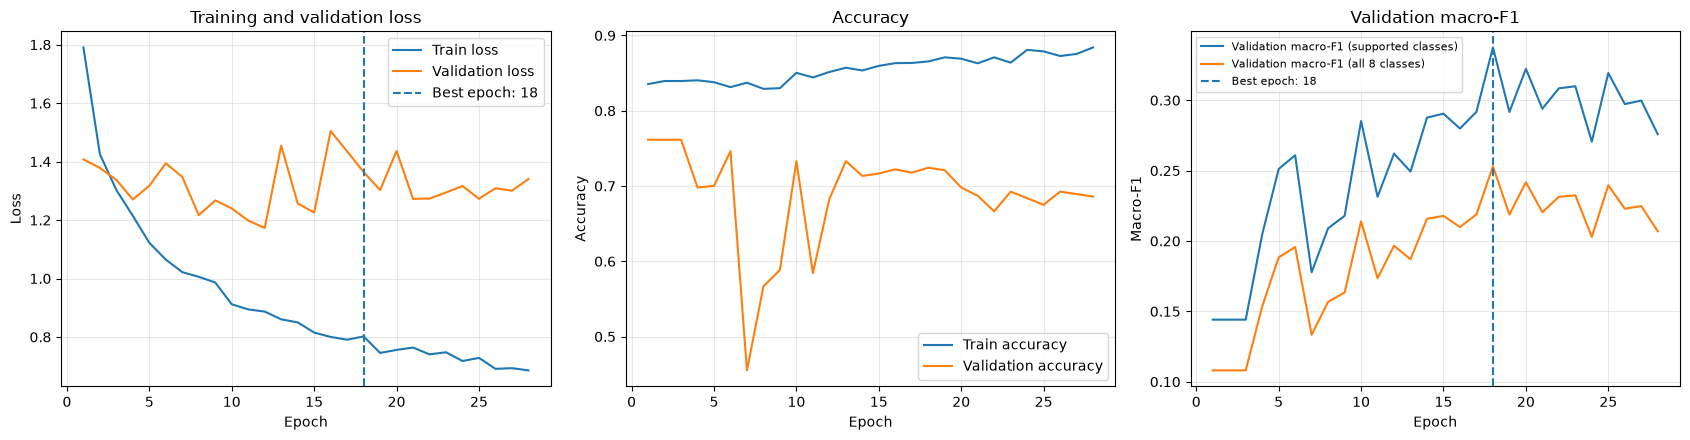

Best epoch: 18
Best supported-class validation macro-F1: 0.3375
Training curves saved: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/training_curves.png


In [27]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.read_csv(HISTORY_PATH)

best_row = history_df.loc[
    history_df["val_macro_f1_supported"].idxmax()
]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Loss
axes[0].plot(
    history_df["epoch"], history_df["train_loss"],
    label="Train loss"
)
axes[0].plot(
    history_df["epoch"], history_df["val_loss"],
    label="Validation loss"
)
axes[0].axvline(
    int(best_row["epoch"]), linestyle="--",
    label=f"Best epoch: {int(best_row['epoch'])}"
)
axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(
    history_df["epoch"], history_df["train_accuracy"],
    label="Train accuracy"
)
axes[1].plot(
    history_df["epoch"], history_df["val_accuracy"],
    label="Validation accuracy"
)
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Macro-F1
axes[2].plot(
    history_df["epoch"],
    history_df["val_macro_f1_supported"],
    label="Validation macro-F1 (supported classes)"
)
axes[2].plot(
    history_df["epoch"],
    history_df["val_macro_f1_all8"],
    label="Validation macro-F1 (all 8 classes)"
)
axes[2].axvline(
    int(best_row["epoch"]), linestyle="--",
    label=f"Best epoch: {int(best_row['epoch'])}"
)
axes[2].set_title("Validation macro-F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro-F1")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()

plot_path = EXPERIMENT_DIR / "training_curves.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Best epoch:", int(best_row["epoch"]))
print(
    "Best supported-class validation macro-F1:",
    round(float(best_row["val_macro_f1_supported"]), 4)
)
print("Training curves saved:", plot_path)

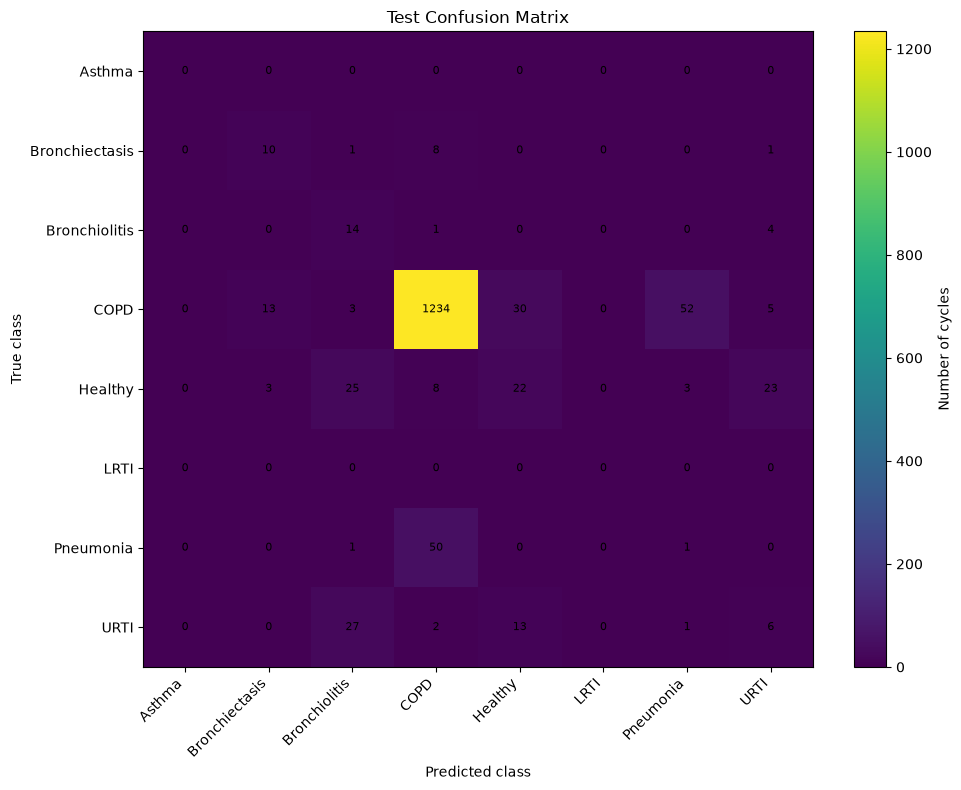

Final test metrics:
{
  "checkpoint_epoch": 18,
  "test_accuracy": 0.8244714926329276,
  "test_balanced_accuracy": 0.4272314118149256,
  "test_macro_f1_all8": 0.2663445597868643,
  "test_macro_f1_supported": 0.35512607971581905,
  "test_weighted_f1": 0.8308395280442986,
  "test_samples": 1561,
  "test_classes_present": [
    "Bronchiectasis",
    "Bronchiolitis",
    "COPD",
    "Healthy",
    "Pneumonia",
    "URTI"
  ],
  "classes_absent_from_test": [
    "Asthma",
    "LRTI"
  ]
}

Per-class test report:


,precision,recall,f1-score,support
Asthma,0.0000,0.0000,0.0000,0.0000
Bronchiectasis,0.3846,0.5000,0.4348,20.0000
Bronchiolitis,0.1972,0.7368,0.3111,19.0000
COPD,0.9470,0.9230,0.9348,1337.0000
Healthy,0.3385,0.2619,0.2953,84.0000
LRTI,0.0000,0.0000,0.0000,0.0000
Pneumonia,0.0175,0.0192,0.0183,52.0000
URTI,0.1538,0.1224,0.1364,49.0000
accuracy,0.8245,0.8245,0.8245,0.8245
macro avg,0.2548,0.3204,0.2663,1561.0000



Artifacts saved in: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn


In [28]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

# Load the saved validation-selected checkpoint.
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)
model.eval()

test_result = run_epoch(model, test_loader, training=False)

y_true = test_result["y_true"]
y_pred = test_result["y_pred"]

# Report all eight classes, including classes with zero test support.
report_dict = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).T
report_df.to_csv(EXPERIMENT_DIR / "test_classification_report.csv")

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
)

metrics = {
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "test_balanced_accuracy": float(
        balanced_accuracy_score(y_true, y_pred)
    ),
    "test_macro_f1_all8": float(
        f1_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0,
        )
    ),
    "test_macro_f1_supported": float(
        f1_score(
            y_true,
            y_pred,
            labels=np.unique(y_true),
            average="macro",
            zero_division=0,
        )
    ),
    "test_weighted_f1": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
    "test_samples": int(len(y_true)),
    "test_classes_present": [
        CLASS_NAMES[i] for i in np.unique(y_true)
    ],
    "classes_absent_from_test": [
        CLASS_NAMES[i]
        for i in range(NUM_CLASSES)
        if i not in np.unique(y_true)
    ],
}

with open(EXPERIMENT_DIR / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

predictions_df = pd.DataFrame({
    "audio_path": test_data["paths"],
    "true_label": y_true,
    "true_class": [CLASS_NAMES[i] for i in y_true],
    "predicted_label": y_pred,
    "predicted_class": [CLASS_NAMES[i] for i in y_pred],
})

predictions_df.to_csv(
    EXPERIMENT_DIR / "test_predictions.csv",
    index=False,
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES,
)
cm_df.to_csv(EXPERIMENT_DIR / "test_confusion_matrix.csv")

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", aspect="auto")
plt.title("Test Confusion Matrix")
plt.colorbar(label="Number of cycles")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.xlabel("Predicted class")
plt.ylabel("True class")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.savefig(
    EXPERIMENT_DIR / "test_confusion_matrix.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Final test metrics:")
print(json.dumps(metrics, indent=2))

print("\nPer-class test report:")
display(report_df.round(4))

print("\nArtifacts saved in:", EXPERIMENT_DIR)

In [29]:
import pandas as pd
import numpy as np

CLASS_NAMES = [
    "Asthma",
    "Bronchiectasis",
    "Bronchiolitis",
    "COPD",
    "Healthy",
    "LRTI",
    "Pneumonia",
    "URTI",
]

split_manifests = {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest,
}

# 1. Count unique patients and cycles per class in each split.
records = []

for split_name, manifest in split_manifests.items():
    for class_id, class_name in enumerate(CLASS_NAMES):
        subset = manifest[manifest["disease_label"] == class_id]

        records.append({
            "split": split_name,
            "class": class_name,
            "cycles": len(subset),
            "unique_patients": subset["patient_id"].nunique(),
        })

patient_support_df = pd.DataFrame(records)

print("CYCLES AND UNIQUE PATIENTS BY CLASS")
display(
    patient_support_df.pivot(
        index="class",
        columns="split",
        values=["cycles", "unique_patients"],
    ).fillna(0).astype(int)
)

# 2. Determine how many distinct patients have each diagnosis overall.
all_manifest = pd.concat(
    list(split_manifests.values()),
    ignore_index=True,
).drop_duplicates(subset=["audio_path"])

overall_records = []

for class_id, class_name in enumerate(CLASS_NAMES):
    subset = all_manifest[
        all_manifest["disease_label"] == class_id
    ]

    overall_records.append({
        "class": class_name,
        "total_cycles": len(subset),
        "unique_patients": subset["patient_id"].nunique(),
        "unique_recordings": subset["recording_id"].nunique(),
    })

overall_support_df = pd.DataFrame(overall_records)

print("\nOVERALL CLASS SUPPORT")
display(overall_support_df)

# 3. Verify patient disjointness across the three splits.
patient_sets = {
    name: set(manifest["patient_id"].unique())
    for name, manifest in split_manifests.items()
}

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = patient_sets[first] & patient_sets[second]
    print(
        f"{first} vs {second}: "
        f"{len(overlap)} overlapping patients"
    )
    if overlap:
        print("Overlapping patient IDs:", sorted(overlap))

print("\nAudit complete. No files or existing splits were modified.")


CYCLES AND UNIQUE PATIENTS BY CLASS


cycles                  unique_patients                 
split            test train validation            test train validation
class                                                                  
Asthma              0     6          0               0     1          0
Bronchiectasis     20    76          8               2     4          1
Bronchiolitis      19   114         27               1     4          1
COPD             1337  3713        696              13    41         10
Healthy            84   194         44               5    17          4
LRTI                0    32          0               0     2          0
Pneumonia          52   121        112               1     4          1
URTI               49   167         27               3     9          2


OVERALL CLASS SUPPORT


,class,total_cycles,unique_patients,unique_recordings
0,Asthma,6,1,1
1,Bronchiectasis,104,7,3
2,Bronchiolitis,160,6,1
3,COPD,5746,64,34
4,Healthy,322,26,3
5,LRTI,32,2,1
6,Pneumonia,285,6,4
7,URTI,243,14,2


train vs validation: 0 overlapping patients
train vs test: 0 overlapping patients
validation vs test: 0 overlapping patients

Audit complete. No files or existing splits were modified.


In [30]:
import pandas as pd

all_manifest = pd.concat(
    [train_manifest, val_manifest, test_manifest],
    ignore_index=True,
)

# Patient-level diagnosis consistency.
patient_diagnoses = (
    all_manifest.groupby("patient_id")
    .agg(
        diagnosis_count=("diagnosis", "nunique"),
        diagnoses=("diagnosis", lambda x: ", ".join(sorted(set(x)))),
        cycle_count=("audio_path", "nunique"),
        split_count=("cnn_split", "nunique"),
        splits=("cnn_split", lambda x: ", ".join(sorted(set(x)))),
    )
    .reset_index()
)

print("Patients with more than one diagnosis:")
display(
    patient_diagnoses[
        patient_diagnoses["diagnosis_count"] > 1
    ]
)

print("\nPatients appearing in multiple splits:")
display(
    patient_diagnoses[
        patient_diagnoses["split_count"] > 1
    ]
)

print("\nRare-class patient mapping:")
rare_classes = [
    "Asthma",
    "LRTI",
    "Bronchiectasis",
    "Bronchiolitis",
    "Pneumonia",
]

rare_mapping = (
    all_manifest[all_manifest["diagnosis"].isin(rare_classes)]
    .drop_duplicates(["patient_id", "diagnosis"])
    [["patient_id", "diagnosis", "cnn_split"]]
    .sort_values(["diagnosis", "patient_id"])
)

display(rare_mapping)

print("\nMetadata audit complete. No files modified.")

Patients with more than one diagnosis:


,patient_id,diagnosis_count,diagnoses,cycle_count,split_count,splits



Patients appearing in multiple splits:


,patient_id,diagnosis_count,diagnoses,cycle_count,split_count,splits



Rare-class patient mapping:


,patient_id,diagnosis,cnn_split
13,103,Asthma,train
90,111,Bronchiectasis,train
4536,116,Bronchiectasis,validation
2519,168,Bronchiectasis,train
6132,169,Bronchiectasis,test
6494,196,Bronchiectasis,test
3801,201,Bronchiectasis,train
4245,215,Bronchiectasis,train
1648,149,Bronchiolitis,train
6113,161,Bronchiolitis,test



Metadata audit complete. No files modified.


In [31]:
from pathlib import Path
import json

LOSS_EXPERIMENT_DIR = EXPERIMENT_DIR / "loss_comparison"
LOSS_EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

loss_experiment_config = {
    "architecture": "LightweightMultiFeatureCNN",
    "parameters": 5408,
    "losses_to_compare": [
        "sqrt_weighted_cross_entropy",
        "focal_loss",
        "effective_number_class_balanced_loss",
    ],
    "selection_metric": "validation_macro_f1_supported",
    "validation_supported_classes": [
        CLASS_NAMES[i] for i in validation_supported_classes
    ],
    "test_usage": "final evaluation only",
    "patient_disjoint_split": True,
    "seed": SEED,
}

with open(
    LOSS_EXPERIMENT_DIR / "experiment_config.json", "w"
) as f:
    json.dump(loss_experiment_config, f, indent=2)

print("Loss-comparison directory:", LOSS_EXPERIMENT_DIR)
print("Configuration saved.")
print("Existing checkpoints and metrics have not been modified.")

Loss-comparison directory: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/lightweight_multifeature_cnn/loss_comparison
Configuration saved.
Existing checkpoints and metrics have not been modified.


In [32]:
import torch
import torch.nn as nn
import numpy as np
import json

# 1. Baseline: existing square-root inverse-frequency weights.
baseline_weights = torch.tensor(
    class_weights, dtype=torch.float32, device=DEVICE
)

baseline_loss = nn.CrossEntropyLoss(
    weight=baseline_weights
)

# 2. Focal loss with moderate class weights.
# The focusing term reduces the relative contribution of easy examples.
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        log_probs = torch.nn.functional.log_softmax(
            logits, dim=1
        )
        log_pt = log_probs.gather(
            1, targets.unsqueeze(1)
        ).squeeze(1)
        pt = log_pt.exp()

        loss = -((1.0 - pt) ** self.gamma) * log_pt

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            loss = loss * alpha_t

        return loss.mean()


focal_loss = FocalLoss(
    alpha=baseline_weights,
    gamma=2.0,
)

# 3. Effective-number class-balanced weights.
# beta is chosen close to 1, but the resulting weights are normalized
# and capped to avoid extreme influence from classes with tiny support.
beta = 0.99

effective_weights = np.zeros(NUM_CLASSES, dtype=np.float64)
for class_id, count in enumerate(train_counts):
    if count > 0:
        effective_weights[class_id] = (
            (1.0 - beta) / (1.0 - beta ** count)
        )

effective_weights /= effective_weights[present].mean()

# Cap weights and renormalize their training-frequency-weighted mean.
effective_weights = np.clip(effective_weights, 0.5, 5.0)
effective_weights /= (
    np.sum(effective_weights * train_counts) / np.sum(train_counts)
)

effective_weights_tensor = torch.tensor(
    effective_weights,
    dtype=torch.float32,
    device=DEVICE,
)

class_balanced_loss = nn.CrossEntropyLoss(
    weight=effective_weights_tensor
)

loss_weights_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "train_count": train_counts.astype(int),
    "baseline_weight": class_weights,
    "class_balanced_weight": effective_weights,
})

display(loss_weights_df)

print("Loss functions defined:")
print("1. Square-root weighted cross-entropy")
print("2. Focal loss (gamma=2)")
print("3. Effective-number class-balanced cross-entropy")

,class,train_count,baseline_weight,class_balanced_weight
0,Asthma,6,14.298261,9.286549
1,Bronchiectasis,76,4.017464,1.017465
2,Bronchiolitis,114,3.280246,0.980905
3,COPD,3713,0.574773,0.980905
4,Healthy,194,2.514536,0.980905
5,LRTI,32,6.191328,1.976031
6,Pneumonia,121,3.183949,0.980905
7,URTI,167,2.710195,0.980905


Loss functions defined:
1. Square-root weighted cross-entropy
2. Focal loss (gamma=2)
3. Effective-number class-balanced cross-entropy
